# Hoang et al. (2016): torsional vibration of a levitated non-spherical nanoparticle

T. M. Hoang, Y. Ma, J. Ahn, J. Bang, F. Robicheaux, Z.-Q. Yin and T. Li, *Torsional Optomechanics
of a Levitated Nonspherical Nanoparticle*, Phys. Rev. Lett. **117**, 123604 (2016),
[doi:10.1103/PhysRevLett.117.123604](https://doi.org/10.1103/PhysRevLett.117.123604)
(open version: arXiv:1605.03990).

A non-spherical nanodiamond in a linearly polarised tweezer aligns its long axis with the
polarisation and librates ("torsional vibration", TOR) about it. Its libration frequency can be an
order of magnitude above its centre-of-mass (COM) frequency, and both scale as $\sqrt{P}$, so their
ratio does not depend on the power. This notebook builds the paper's ellipsoidal model in levisim
(`Spheroid`, `Tweezer`, `Trap.Ωθ`, `RigidBodySimulation`) and compares

1. the model frequencies of the text: **Ωθ/2π = 1.26 MHz and Ωy/2π = 220 kHz** for a diamond
   ellipsoid with semi-axes 50, 40, 40 nm, a 600 nm waist, 1550 nm and 100 mW (caption of Fig. 3),
   and the susceptibilities χx = 2.05, χy = 1.74 quoted for this aspect ratio;
2. the power independence of Ωθ/Ωx,y (Fig. 2d) and the √P law (Fig. 2b);
3. the enhancement ratio against size and aspect ratio (Fig. 3d);
4. the measured ratio ≈ 6 (Fig. 2a: Ωθ/2π = 1.0 MHz, Ωx/2π = 0.16 MHz, Ωy/2π = 0.18 MHz), a
   qualitative comparison, since the nanodiamonds are irregular;
5. a time-domain check: the spectrum of a `RigidBodySimulation` of the trapped ellipsoid shows the
   COM and TOR peaks at the linear-model frequencies.

**Comparison stated before running:** levisim's `Trap.Ωθ['γ']` and `Trap.Ωj['x']` against the paper's
1.26 MHz and 220 kHz (its Eq. (2)), expected within 1 %.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| particle | diamond ellipsoid, semi-axes $r_x$ = 50 nm, $r_y = r_z$ = 40 nm (prolate spheroid) | Fig. 3 caption |
| material | diamond, ρ = 3515 kg/m³, $n$(1550 nm) from levisim's library (`DIAMOND`) | levisim materials (the paper states neither) |
| tweezer | 1550 nm, 100 mW, round waist $W_t$ = 600 nm, linear polarisation | Fig. 3 caption |
| experiment | ~500 mW, 100 Torr, 1550 nm | Fig. 2a caption and text |

Axes: the paper's polarisation is its $x$ axis and the TOR mode is the rotation about the beam
axis $z_T$. levisim's tweezer is polarised along $y$, so the paper's $x$, $y$ are levisim's $y$, $x$,
its $\Omega_y$ is levisim's $\Omega_x$ and its $\Omega_\theta$ is the libration `'γ'` (rotation about
the lab $z$ axis). The libration `'α'` (rotation about $x$, the tilt towards the beam axis) is not in
the paper's two-dimensional model.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

from levisim.core.constants import c, ε0, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, MHz, mW, nm, mbar
from levisim.physics import Gas, Spheroid, Trap, Tweezer
from levisim.physics.materials import DIAMOND
from levisim.physics.particle import body_axis_to_quaternion
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()
along_y = body_axis_to_quaternion((0, 1, 0))


def ellipsoid(rx, ry, **kwargs):
    """The paper's ellipsoid (semi-axes rx > ry = rz), its long axis along levisim's polarisation y"""
    return Spheroid(a=rx, b=ry, material=DIAMOND, λ=1550*nm, orientation=along_y, **kwargs)


def tweezer(P=100*mW, Wt=600*nm):
    return Tweezer(λ=1550*nm, wx0=Wt, wy0=Wt, Power=P)


particle = ellipsoid(50*nm, 40*nm)
trap = Trap(tweezer=tweezer(), particle=particle)
χ = np.diag(particle.static_polarisability_tensor()) / (ε0 * particle.V)
print(f'εr(1550 nm) = {particle.εr:.4f};  χ along the long axis = {χ[2]:.3f} (paper 2.05), across = {χ[0]:.3f} (paper 1.74)')
Ωx, Ωy, Ωz = (trap.Ωj[a] for a in 'xyz')
Ωγ, Ωα = trap.Ωθ['γ'], trap.Ωθ['α']
print(f'levisim: Ωθ/2π = Ωγ/2π = {Ωγ / MHz:.4f} MHz (paper 1.26 MHz), Ωx/2π = {Ωx / kHz:.2f} kHz (paper Ωy/2π = 220 kHz)')
print(f'         ratio Ωθ/Ω = {Ωγ / Ωx:.3f} (paper 1.26/0.220 = {1.26 / 0.220:.3f})')
print(f'         also: Ωy/2π (along the polarisation) = {Ωy / kHz:.1f} kHz, Ωz/2π = {Ωz / kHz:.1f} kHz, libration α/2π = {Ωα / MHz:.4f} MHz')

# the paper's Eq. (2), evaluated with levisim's χ and ρ (Ω in rad/s)
P, Wt, ρ = 100*mW, 600*nm, DIAMOND.ρ
Ωy_eq2 = np.sqrt(4 * χ[2] * P / (c * π * ρ * Wt**4))
Ωθ_eq2 = np.sqrt(10 * (χ[2] - χ[0]) * P / (c * π * ρ * Wt**2 * ((50*nm)**2 + (40*nm)**2)))
print(f'Eq. (2) with these χ, ρ: Ωθ/2π = {Ωθ_eq2 / (2 * π) / 1e6:.4f} MHz, Ωy/2π = {Ωy_eq2 / (2 * π) / 1e3:.2f} kHz; '
      f'levisim/Eq. (2) - 1 = {Ωγ / Ωθ_eq2 - 1:+.2e}, {Ωx / Ωy_eq2 - 1:+.2e} (levisim includes the radiation reaction)')

εr(1550 nm) = 5.7015;  χ along the long axis = 2.046 (paper 2.05), across = 1.740 (paper 1.74)
levisim: Ωθ/2π = Ωγ/2π = 1.2600 MHz (paper 1.26 MHz), Ωx/2π = 219.83 kHz (paper Ωy/2π = 220 kHz)
         ratio Ωθ/Ω = 5.732 (paper 1.26/0.220 = 5.727)
         also: Ωy/2π (along the polarisation) = 219.8 kHz, Ωz/2π = 127.8 kHz, libration α/2π = 1.2600 MHz
Eq. (2) with these χ, ρ: Ωθ/2π = 1.2600 MHz, Ωy/2π = 219.83 kHz; levisim/Eq. (2) - 1 = -7.56e-06, -2.94e-06 (levisim includes the radiation reaction)


levisim's `Trap.Ωθ` comes from the torque stiffness $K = \tfrac12 E_0^2\,\mathrm{Re}(\alpha_\parallel - \alpha_\perp)$
and the moment of inertia $I = m(r_x^2 + r_y^2)/5$, which is the curvature of the paper's Eq. (1)
$U = -\tfrac{V}{2c}[\chi_x - (\chi_x - \chi_y)\sin^2\theta]\,I_L$. The depolarisation factors of the
spheroid give the paper's quoted susceptibilities.

## Power dependence (Figs. 2b and 2d)

Ωθ ∝ P^0.500000; ratio Ωθ/Ωx from 5.731744 to 5.731744 over 50-500 mW


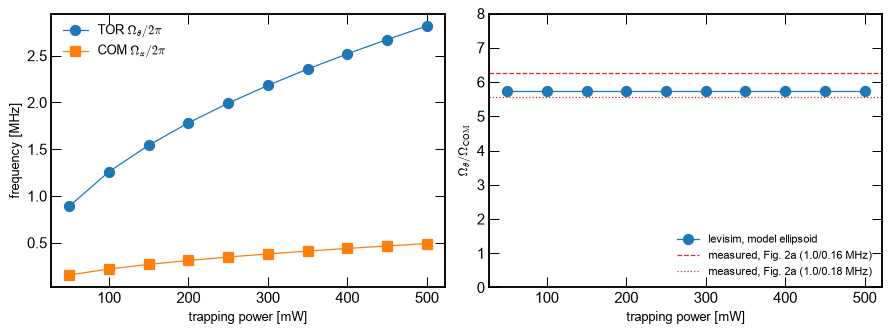

In [2]:
powers = np.linspace(50, 500, 10) * mW
Ωθs = np.array([Trap(tweezer=tweezer(P), particle=particle).Ωθ['γ'] for P in powers])
Ωxs = np.array([Trap(tweezer=tweezer(P), particle=particle).Ωj['x'] for P in powers])
exponent = np.polyfit(np.log(powers), np.log(Ωθs), 1)[0]
print(f'Ωθ ∝ P^{exponent:.6f}; ratio Ωθ/Ωx from {np.min(Ωθs / Ωxs):.6f} to {np.max(Ωθs / Ωxs):.6f} over 50-500 mW')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(powers / mW, Ωθs / MHz, 'o-', label=r'TOR $\Omega_\theta/2\pi$')
axes[0].plot(powers / mW, Ωxs / MHz, 's-', label=r'COM $\Omega_x/2\pi$')
axes[0].set_xlabel('trapping power [mW]')
axes[0].set_ylabel('frequency [MHz]')
axes[0].legend(frameon=False)
axes[1].plot(powers / mW, Ωθs / Ωxs, 'o-', label='levisim, model ellipsoid')
axes[1].axhline(1.0 / 0.16, color='C3', ls='--', label='measured, Fig. 2a (1.0/0.16 MHz)')
axes[1].axhline(1.0 / 0.18, color='C3', ls=':', label='measured, Fig. 2a (1.0/0.18 MHz)')
axes[1].set_xlabel('trapping power [mW]')
axes[1].set_ylabel(r'$\Omega_\theta/\Omega_\mathrm{COM}$')
axes[1].set_ylim(0, 8)
axes[1].legend(frameon=False, fontsize=9, loc='lower right')
fig.tight_layout()

Both frequencies scale as $\sqrt P$ to numerical precision and the ratio is independent of power,
as in Fig. 2d. The model ellipsoid's ratio (5.73) is close to the measured 5.6-6.3 of the
nanodiamond of Fig. 2a, whose shape and size are not known.

## Enhancement ratio against size and aspect ratio (Fig. 3d)

ry = 0.5 rx: ratio 17.50 at 2rx = 60 nm, 7.00 at 150 nm
ry = 0.8 rx: ratio 9.55 at 2rx = 60 nm, 3.82 at 150 nm
ry = 0.9 rx: ratio 6.40 at 2rx = 60 nm, 2.56 at 150 nm


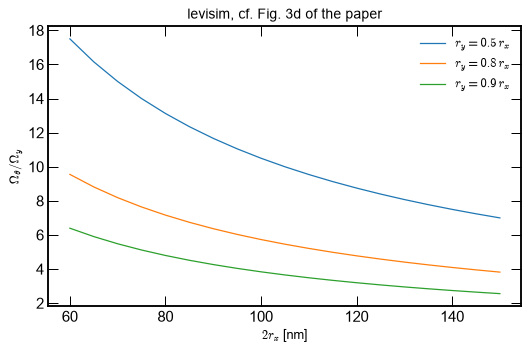

In [3]:
sizes = np.linspace(60, 150, 19) * nm  # 2 rx
fig, ax = plt.subplots(figsize=(6, 4))
table = {}
for aspect in (0.5, 0.8, 0.9):
    ratios = []
    for size in sizes:
        rx = size / 2
        tr = Trap(tweezer=tweezer(), particle=ellipsoid(rx, aspect * rx))
        ratios.append(tr.Ωθ['γ'] / tr.Ωj['x'])
    table[aspect] = np.array(ratios)
    ax.plot(sizes / nm, ratios, label=f'$r_y = {aspect}\\,r_x$')
ax.set_xlabel(r'$2r_x$ [nm]')
ax.set_ylabel(r'$\Omega_\theta/\Omega_y$')
ax.set_title('levisim, cf. Fig. 3d of the paper', fontsize=11)
ax.legend(frameon=False)
fig.tight_layout()
for aspect, ratios in table.items():
    print(f'ry = {aspect} rx: ratio {ratios[0]:.2f} at 2rx = 60 nm, {ratios[-1]:.2f} at 150 nm')

The ratio grows as the particle gets smaller and more elongated ($\Omega_\theta/\Omega_y \propto W_t/r_x$
at a fixed aspect ratio), the trend of Fig. 3d, whose curves are read only qualitatively here.

## Time domain: COM and TOR peaks of a `RigidBodySimulation`

The trapped ellipsoid is simulated with gas damping at 1 mbar (the paper's 100 Torr would overdamp
the COM motion), with the gas at room temperature and at 3 K, and the spectra of $x$ and of the tilt
of the long axis towards $x$ (the TOR angle) are compared with the linear-model frequencies.

gas at 300.0 K: simulated peaks TOR 1.086 MHz (linear model 1.260), COM x 207.5 kHz (linear model 219.8); rms TOR angle 0.324 rad; resolution 12.2 kHz
gas at   3.0 K: simulated peaks TOR 1.257 MHz (linear model 1.260), COM x 219.7 kHz (linear model 219.8); rms TOR angle 0.027 rad; resolution 12.2 kHz


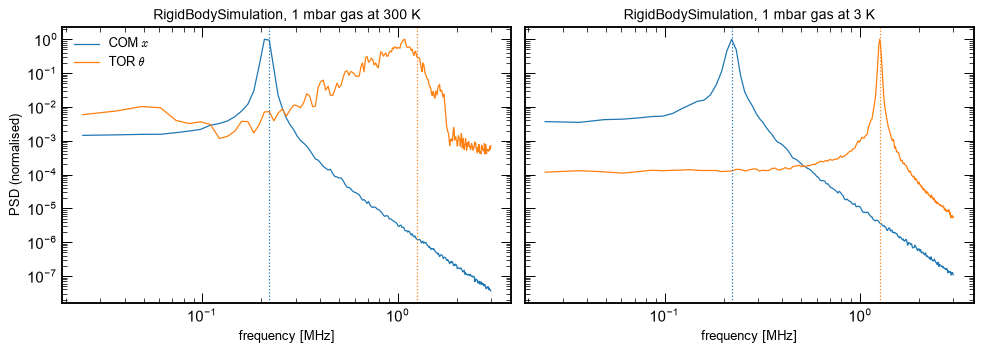

In [4]:
Δt = 10e-9
results = {}
for T in (300.0, 3.0):
    trap_sim = Trap(tweezer=tweezer(), particle=ellipsoid(50*nm, 40*nm), gas=Gas(P=1*mbar, T=T))
    sim = RigidBodySimulation(trap=trap_sim, num_samples=1_000_000, Δt=Δt, seed=7)
    θ_tor = -sim.lab_directions((0, 0, 1))[200_000:, 0]
    x = sim.positions[200_000:, 0]
    f, G_θ = welch(θ_tor, fs=1 / Δt, nperseg=2**13)
    _, G_x = welch(x, fs=1 / Δt, nperseg=2**13)
    peak_θ = f[np.argmax(G_θ * (f > 500e3))]
    peak_x = f[np.argmax(G_x * (f > 50e3))]
    results[T] = (f, G_x, G_θ)
    print(f'gas at {T:5.1f} K: simulated peaks TOR {peak_θ / 1e6:.3f} MHz (linear model {trap_sim.Ωθ["γ"] / MHz:.3f}), '
          f'COM x {peak_x / 1e3:.1f} kHz (linear model {trap_sim.Ωj["x"] / kHz:.1f}); rms TOR angle {np.std(θ_tor):.3f} rad; '
          f'resolution {f[1] / 1e3:.1f} kHz')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax1, (T, (f, G_x, G_θ)) in zip(axes, results.items()):
    mask = (f > 20e3) & (f < 3e6)
    ax1.loglog(f[mask] / 1e6, G_x[mask] / np.max(G_x[mask]), label='COM $x$')
    ax1.loglog(f[mask] / 1e6, G_θ[mask] / np.max(G_θ[mask]), label=r'TOR $\theta$')
    for value, colour in ((trap.Ωj['x'], 'C0'), (trap.Ωθ['γ'], 'C1')):
        ax1.axvline(value / MHz, color=colour, ls=':', lw=1)
    ax1.set_xlabel('frequency [MHz]')
    ax1.set_title(f'RigidBodySimulation, 1 mbar gas at {T:g} K', fontsize=11)
axes[0].set_ylabel('PSD (normalised)')
axes[0].legend(frameon=False)
fig.tight_layout()

At room temperature the thermal libration of this weakly anisotropic ellipsoid is large (rms ≈ 0.26 rad),
so the $\sin^2\theta$ potential of Eq. (1) is far from harmonic and the TOR peak is pulled down and
broadened (to about 1.09 MHz here, rms angle ≈ 0.3 rad). The COM peak moves down too (to about
208 kHz), because a librating particle presents a smaller average polarisability along the
polarisation and samples the anharmonic beam profile. With the gas at 3 K the
motion is small and both peaks sit at the linear-model frequencies; the linear frequencies are the
ones the paper's Eq. (2) gives.

## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| χ along / across the long axis (ry = 0.8 rx) | 2.05 / 1.74 | 2.046 / 1.740 | agree |
| Ωθ/2π (model ellipsoid, 100 mW, 600 nm, 1550 nm) | 1.26 MHz | 1.260 MHz | agree (< 0.1 %) |
| Ωy/2π (COM across the polarisation) | 220 kHz | 219.8 kHz | agree (0.1 %) |
| Ωθ/Ω against power | constant (Fig. 2d) | constant to round-off, Ωθ ∝ P^0.5 | agree |
| ratio against size and aspect (Fig. 3d) | grows for small, elongated particles | same trend | qualitative |
| measured ratio (Fig. 2a) | 1.0/0.16 = 6.3, 1.0/0.18 = 5.6 | model ellipsoid 5.73 | consistent (shape of the measured particle unknown) |
| time domain | — | at a 3 K gas the simulated TOR and COM peaks sit at the linear-model frequencies; at 300 K the TOR peak is pulled to ≈ 1.09 MHz and the COM peak to ≈ 208 kHz by the anharmonic motion | consistency check; the room-temperature shift is a levisim prediction, not in the paper |

Not reproduced: the measured spectra themselves (the particles are irregular and their sizes are
not given), the quality factors of Fig. 3c (the paper uses an accommodation coefficient of 0.9;
levisim's `Trap` uses full accommodation) and the proposed cavity cooling.

In [5]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 8.0 s
